# 06 · Where should the plan act first? (Star-risk targeting + ROI)

Turns the scorecard into a prioritized list a health plan can act on. Two risk
dimensions:
- **Readmission burden** — excess 30-day readmissions above a benchmark, which feed the
  Medicare Advantage "Plan All-Cause Readmissions" Star measure and cost money.
- **Patient experience** — low HCAHPS star carried by many surveyed patients, which feeds
  the member-experience (CAHPS) Star measures.

**Proxies (stated plainly):** we don't have the plan's membership, so CMS case
**denominators** and HCAHPS **survey counts** stand in for "how much of the plan's care
flows through each hospital." Cost per readmission is a public range. Benchmarks are
computed from the data (NM and national), not looked up.

In [3]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src.viz import apply_style, CATEGORICAL, WORSE, BETTER, NO_DIFFERENT, INK2, MUTED, SURFACE
apply_style()

RAW = Path("../data/raw")
INTERIM = Path("../data/interim")
PROCESSED = Path("../data/processed")
FIG = Path("../reports/figures")

COST_LOW, COST_HIGH = 15_200, 16_300   # public avg cost per hospital readmission (Medicare / AHRQ range)

# condition-specific readmission measures that have cases + a rate
READM = ["READM_30_AMI", "READM_30_CABG", "READM_30_COPD",
         "READM_30_HF", "READM_30_HIP_KNEE", "READM_30_PN"]

## 1) Readmission benchmarks (national and NM)

For each measure, the volume-weighted average readmission rate across all US hospitals
(national) and across NM hospitals. Computed from the raw file so nothing is looked up.

In [4]:
raw = pd.read_csv(RAW / "unplanned_hospital_visits.csv", dtype=str, keep_default_na=False)
raw["score"] = pd.to_numeric(raw["Score"], errors="coerce")
raw["den"] = pd.to_numeric(raw["Denominator"], errors="coerce")

rows = []
benchmark = {}
for mid in READM:
    us = raw[(raw["Measure ID"] == mid) & raw["score"].notna() & raw["den"].notna()]
    nm = us[us["State"] == "NM"]
    natl = np.average(us["score"], weights=us["den"])
    nmavg = np.average(nm["score"], weights=nm["den"])
    benchmark[mid] = {"national": natl, "nm": nmavg}
    rows.append({"measure": mid, "national %": round(natl, 1),
                 "NM avg %": round(nmavg, 1), "NM hospitals": len(nm)})

benchmarks = pd.DataFrame(rows)
display(benchmarks)

,measure,national %,NM avg %,NM hospitals
0,READM_30_AMI,14.3,13.9,12
1,READM_30_CABG,10.9,11.0,5
2,READM_30_COPD,20.0,19.7,20
3,READM_30_HF,21.3,20.8,25
4,READM_30_HIP_KNEE,5.6,5.5,9
5,READM_30_PN,17.5,16.7,33


## 2) Excess readmissions and dollar impact

For each NM hospital above a benchmark, excess readmissions = cases x (rate - benchmark).
Hospitals at or below the benchmark contribute zero (you can't "avoid" below-average
readmissions). We total against both benchmarks and apply the cost range.

Excess readmissions vs national: 35
Excess readmissions vs NM avg : 72
Dollar impact vs national: $538,339 - $577,298
Dollar impact vs NM avg : $1,095,417 - $1,174,690


,Facility ID,Facility Name,excess_vs_national,excess_vs_nm
14,32005F,VA NEW MEXICO HEALTHCARE SYSTEM,8.9,14.9
8,320018,MEMORIAL MEDICAL CENTER,8.7,13.0
4,320006,EASTERN NEW MEXICO MEDICAL CENTER,4.4,8.2
23,320091,THREE CROSSES REGIONAL HOSPITAL LLC,3.7,6.9
9,320021,PRESBYTERIAN HOSPITAL,2.8,4.5
5,320009,LOVELACE MEDICAL CENTER,1.9,2.2
20,320085,MOUNTAIN VIEW REGIONAL MEDICAL CENTER,1.4,6.6
16,320063,CARLSBAD MEDICAL CENTER,0.9,2.7


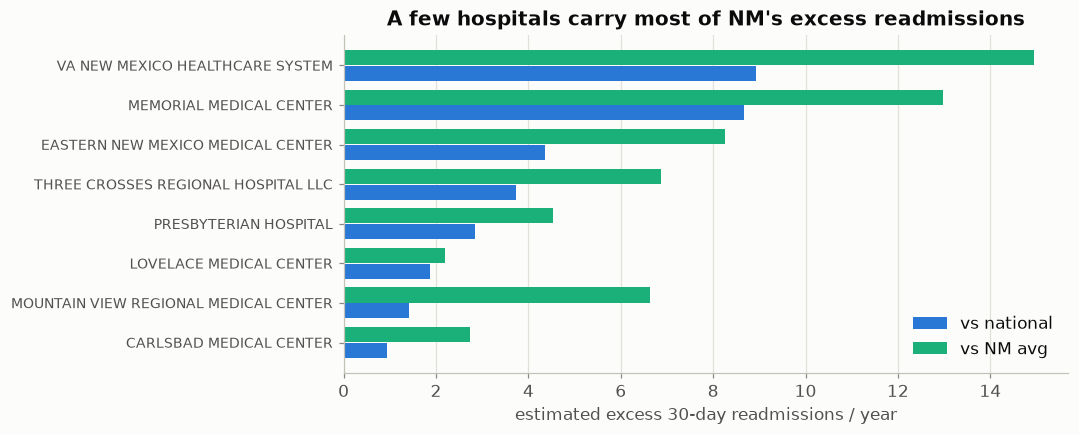

In [5]:
nm = raw[(raw["State"] == "NM") & raw["Measure ID"].isin(READM)
         & raw["score"].notna() & raw["den"].notna()].copy()

def excess(row, which):
    b = benchmark[row["Measure ID"]][which]
    return max(0.0, row["score"] - b) / 100 * row["den"]

nm["excess_vs_national"] = nm.apply(lambda r: excess(r, "national"), axis=1)
nm["excess_vs_nm"] = nm.apply(lambda r: excess(r, "nm"), axis=1)

tot_natl = nm["excess_vs_national"].sum()
tot_nm = nm["excess_vs_nm"].sum()
print(f"Excess readmissions vs national: {tot_natl:.0f}")
print(f"Excess readmissions vs NM avg : {tot_nm:.0f}")
print(f"Dollar impact vs national: ${tot_natl*COST_LOW:,.0f} - ${tot_natl*COST_HIGH:,.0f}")
print(f"Dollar impact vs NM avg : ${tot_nm*COST_LOW:,.0f} - ${tot_nm*COST_HIGH:,.0f}")

by_h = (nm.groupby(["Facility ID", "Facility Name"])[["excess_vs_national", "excess_vs_nm"]]
        .sum().reset_index().sort_values("excess_vs_national", ascending=False))
display(by_h.head(8).round(1))

top = by_h.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4))
y = np.arange(len(top))
ax.barh(y - 0.2, top["excess_vs_national"], height=0.38, color=CATEGORICAL[0], label="vs national")
ax.barh(y + 0.2, top["excess_vs_nm"], height=0.38, color=CATEGORICAL[1], label="vs NM avg")
ax.set_yticks(y)
ax.set_yticklabels(top["Facility Name"], fontsize=9)
ax.set_xlabel("estimated excess 30-day readmissions / year")
ax.set_title("A few hospitals carry most of NM's excess readmissions")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "fig_excess_readmissions.png")
plt.show()

In [6]:
# how concentrated is NM's excess? top 3 hospitals vs NM's total, under each benchmark
top3 = by_h.head(3)
pd.DataFrame({
    "benchmark": ["national", "NM avg"],
    "NM excess (total)": [tot_natl, tot_nm],
    "top 3 hospitals": [top3["excess_vs_national"].sum(), top3["excess_vs_nm"].sum()],
    "top 3 share (%)": [top3["excess_vs_national"].sum() / tot_natl * 100,
                        top3["excess_vs_nm"].sum() / tot_nm * 100],
}).round(0)

,benchmark,NM excess (total),top 3 hospitals,top 3 share (%)
0,national,35.0,22.0,62.0
1,NM avg,72.0,36.0,50.0


## 3) Patient-experience risk

Low HCAHPS star carried by many surveyed patients is the experience-Star exposure. We
weight the experience gap (how far below a 5-star) by survey volume.

In [7]:
hc = pd.read_csv(INTERIM / "hcahps_nm.csv", dtype={"Facility ID": str})
star = hc[hc["HCAHPS Measure ID"] == "H_STAR_RATING"][
    ["Facility ID", "Facility Name", "value", "completed_surveys"]
].rename(columns={"value": "hcahps_star"}).dropna(subset=["hcahps_star"])

# experience exposure = (5 - star) x surveys : low star + many patients = most risk
star["experience_exposure"] = (5 - star["hcahps_star"]) * star["completed_surveys"]
exp_top = star.sort_values("experience_exposure", ascending=False).head(8)
display(exp_top[["Facility Name", "hcahps_star", "completed_surveys", "experience_exposure"]]
        .reset_index(drop=True))

,Facility Name,hcahps_star,completed_surveys,experience_exposure
0,PRESBYTERIAN HOSPITAL,2.0,5750.0,17250.0
1,UNM HOSPITAL,2.0,1884.0,5652.0
2,MEMORIAL MEDICAL CENTER,2.0,1078.0,3234.0
3,LOVELACE MEDICAL CENTER,3.0,928.0,1856.0
4,MOUNTAIN VIEW REGIONAL MEDICAL CENTER,2.0,513.0,1539.0
5,LOVELACE WOMEN'S HOSPITAL,2.0,493.0,1479.0
6,SAN JUAN REGIONAL MEDICAL CENTER INC,2.0,381.0,1143.0
7,EASTERN NEW MEXICO MEDICAL CENTER,2.0,357.0,1071.0


The lower the experience_exposure the better

## 4) Combined target list

Join the two dimensions. A hospital can be a target on readmissions, on experience, or
both. Save the list for the memo.

Saved: ../data/processed/targets.csv | 33 rows


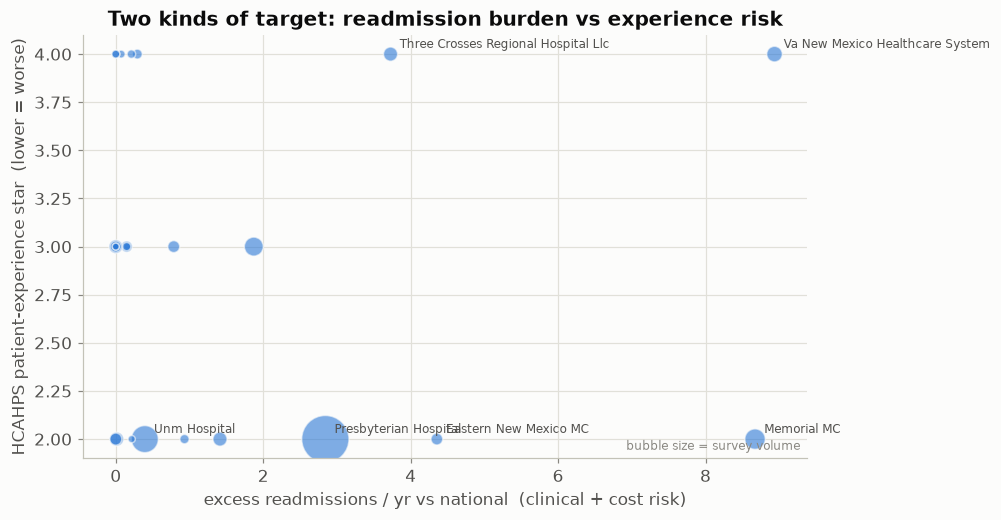

In [8]:
targets = by_h.merge(
    star[["Facility ID", "hcahps_star", "completed_surveys", "experience_exposure"]],
    on="Facility ID", how="outer"
)
targets["dollars_vs_national_low"] = (targets["excess_vs_national"] * COST_LOW).round(0)
targets["dollars_vs_national_high"] = (targets["excess_vs_national"] * COST_HIGH).round(0)
targets = targets.sort_values("excess_vs_national", ascending=False)
targets.to_csv(PROCESSED / "targets.csv", index=False)
print("Saved:", PROCESSED / "targets.csv", "|", len(targets), "rows")

# two-dimensional view: readmission excess (x) vs experience star (y), size = survey volume
plot = targets.dropna(subset=["hcahps_star"]).copy()
fig, ax = plt.subplots(figsize=(8.5, 5))
sizes = plot["completed_surveys"].fillna(100) / 6
sc = ax.scatter(plot["excess_vs_national"], plot["hcahps_star"], s=sizes,
                color=CATEGORICAL[0], alpha=0.6, edgecolor=SURFACE, linewidth=1)
for _, r in plot.iterrows():
    if r["excess_vs_national"] > 3 or (r["hcahps_star"] <= 2 and r["completed_surveys"] > 800):
        ax.annotate(r["Facility Name"].title().replace(" Medical Center", " MC"),
                    (r["excess_vs_national"], r["hcahps_star"]),
                    fontsize=8, color=INK2, xytext=(6, 4), textcoords="offset points")
ax.set_xlabel("excess readmissions / yr vs national  (clinical + cost risk)")
ax.set_ylabel("HCAHPS patient-experience star  (lower = worse)")
ax.set_title("Two kinds of target: readmission burden vs experience risk")
ax.text(0.99, 0.02, "bubble size = survey volume", transform=ax.transAxes,
        ha="right", color=MUTED, fontsize=8)
fig.savefig(FIG / "fig_target_quadrant.png")
plt.show()

## Takeaway — targeting (question: where to act)

- **The readmission opportunity is real but modest:** 
  - Excess readmissions vs national: 35
  - Excess readmissions vs NM avg : 72
  - roughly **$0.5M-$1.2M/yr** is potentially avoidable
- NM as a whole sits near the national readmission rate, so this is a focused opportunity.
- **It concentrates in a few hospitals:** VA NM, Memorial Medical Center and Eastern NM
  carry most of the excess readmissions - the clinical/cost targets.


- **Experience risk is different compared to readmission:** 
  - NM's highest volume hospitals (Presbyterian, UNM, Memorial) - are all 2 stars. so most patients get low rated care. 
- **So there isn't one target, there are two lists:** 
  - List 1 — readmission targets
    - Hospitals: (highest excess readmissions)
      - VA NM
      - Memorial
      - Eastern NM 
    - Suggestions: 
      - **follow up phone call within 48 hours of discharge**, since many problems surface within the first couple of days, a call would catch it while it is fixible in a clinic instead of at the ER. It spots medical confusion or worsening symptoms before it becomes a readmission.
      
      - **medication reconciliation**: someone sits down and compares the new discharge list against what the patient was already taking, and resolves the conflicts before they walk out the door
      - **booking the post-discharge appointment**: scheduling an appointment before the patient leaves, that is scheduled within 7 days. that way there is time to catch something early on, before complications spiral out of control
      - **transitions of care**: because sometimes handoff fails and the patient gets lost/confused, and end up back at the ER. follow up calls that happen more frequently can greatly reduce readmissions
    - Goal: cut avoidable readmissions → save money
  - List 2 — experience targets
    - Hospitals: (low star across the most patients)
      - Presbyterian
      - UNM
      - Memorial 
    - Suggestions: 
      - **better communication**: to see how well did the nurse/doctor did on explaining things, listening, and whether or not they treated the patient with courtesey. if they felt that was low, that they were rushed, and disregarded, fixing it would significantly increase the score
      - **clearer discharge instructions**: knowing what symptoms to watchout for 
      - **responsiveness**: when the patient needed help, how soon were they able to get it. and then to adjust the priorities accordingly
    - Goal: raise patient-experience scores → lift the plan's Star rating

w